# Beauty360 — Exploration du catalogue ivoirien

**Source :** 63 soins du visage vendus sur **Jumia Côte d'Ivoire**, prix relevés le **11/11/2026** (colonne `url_source` = page exacte du produit).

**Pourquoi ce catalogue ?** L'ancien catalogue (Amazon USA, prix en dollars) ne correspondait pas aux utilisatrices ivoiriennes : marques introuvables à Abidjan, prix non pertinents.

**Comment les produits sont étiquetés :** les colonnes `problemes` et `types_peau` reprennent ce que la marque annonce dans le nom du produit (ex. « anti-points noirs », « peaux grasses »). `texture_legere` = gel, fluide, eau ou sérum léger, adapté au climat chaud et humide.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/catalogue_ci.csv")
print(df.shape)
df.head()

(63, 14)


,id,nom,marque,categorie,prix_fcfa,prix_barre_fcfa,problemes,types_peau,texture_legere,utilisation,vendeur,url_source,image_source,date_releve
0,0,La Roche Posay Gel Purifiant Micro-Peeling Eff...,La Roche-Posay,Nettoyant,16950,22000.0,acne|points_noirs|points_blancs|pores|peau_grasse,grasse|mixte,1,matin et soir,Jumia Côte d'Ivoire,https://www.jumia.ci/la-roche-posay-gel-purifi...,https://ci.jumia.is/unsafe/fit-in/520x520/filt...,2026-11-11
1,1,La Roche Posay EFFACLAR DUO Crème hydratante A...,La Roche-Posay,Soin ciblé,15000,NaN,acne|points_noirs|points_blancs|taches,grasse|mixte,1,matin et/ou soir,Jumia Côte d'Ivoire,https://www.jumia.ci/la-roche-posay-effaclar-d...,https://ci.jumia.is/unsafe/fit-in/520x520/filt...,2026-11-11
2,2,Eau Micellaire La Roche-Posay Effaclar Ultra P...,La Roche-Posay,Nettoyant,15600,NaN,peau_grasse|acne,grasse|mixte,1,matin et soir,Jumia Côte d'Ivoire,https://www.jumia.ci/generic-eau-micellaire-la...,https://ci.jumia.is/unsafe/fit-in/520x520/filt...,2026-11-11
3,3,La Roche Effaclar Mat Hydratant Sébo-Régulateu...,La Roche-Posay,Hydratant,15000,NaN,peau_grasse|pores,grasse|mixte,1,matin,Jumia Côte d'Ivoire,https://www.jumia.ci/la-roche-effaclar-mat-hyd...,https://ci.jumia.is/unsafe/fit-in/520x520/filt...,2026-11-11
4,4,Sérum Anti-Imperfections La Roche-Posay Effacl...,La Roche-Posay,Soin ciblé,32500,NaN,acne|points_noirs|points_blancs|pores|taches,grasse|mixte,1,soir,Jumia Côte d'Ivoire,https://www.jumia.ci/generic-serum-anti-imperf...,https://ci.jumia.is/unsafe/fit-in/520x520/filt...,2026-11-11


## 1. Qualité des données

In [2]:
print("Valeurs manquantes :")
print(df.isna().sum())
print("\nDoublons de nom :", df["nom"].duplicated().sum())
print("Prix entre", df["prix_fcfa"].min(), "et", df["prix_fcfa"].max(), "FCFA")

Valeurs manquantes :
id                  0
nom                 0
marque              0
categorie           0
prix_fcfa           0
prix_barre_fcfa    25
problemes           0
types_peau          0
texture_legere      0
utilisation         0
vendeur             0
url_source          0
image_source        0
date_releve         0
dtype: int64

Doublons de nom : 0
Prix entre 3650 et 32500 FCFA


## 2. Répartition par étape de routine et par marque

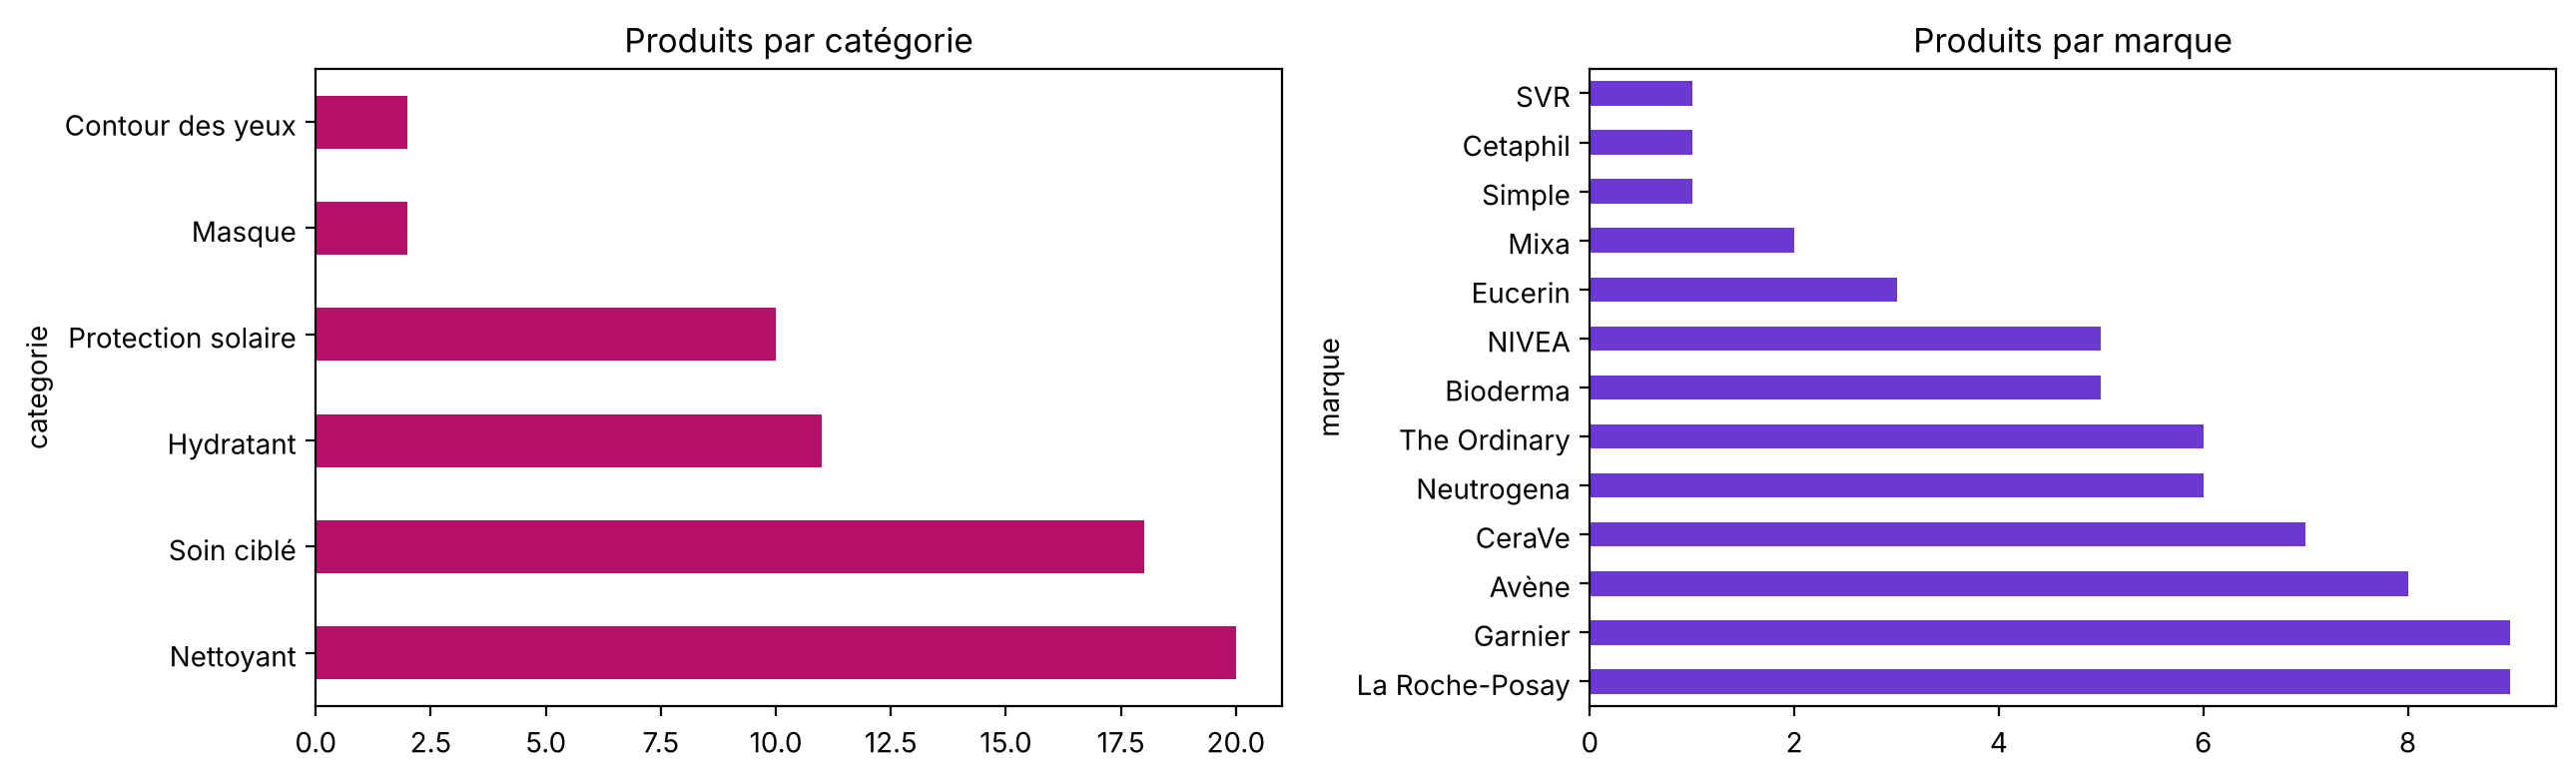

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df["categorie"].value_counts().plot.barh(ax=ax[0], color="#B5106A", title="Produits par catégorie")
df["marque"].value_counts().plot.barh(ax=ax[1], color="#6B38D4", title="Produits par marque")
plt.tight_layout(); plt.show()

## 3. Les prix en FCFA

                    count      min      50%      max
categorie                                           
Contour des yeux      2.0  10400.0  10600.0  10800.0
Hydratant            11.0   7410.0  13100.0  17600.0
Masque                2.0   7200.0   9100.0  11000.0
Nettoyant            20.0   3650.0   9962.0  16950.0
Protection solaire   10.0   7980.0  13508.0  19000.0
Soin ciblé           18.0   4676.0   8178.0  32500.0


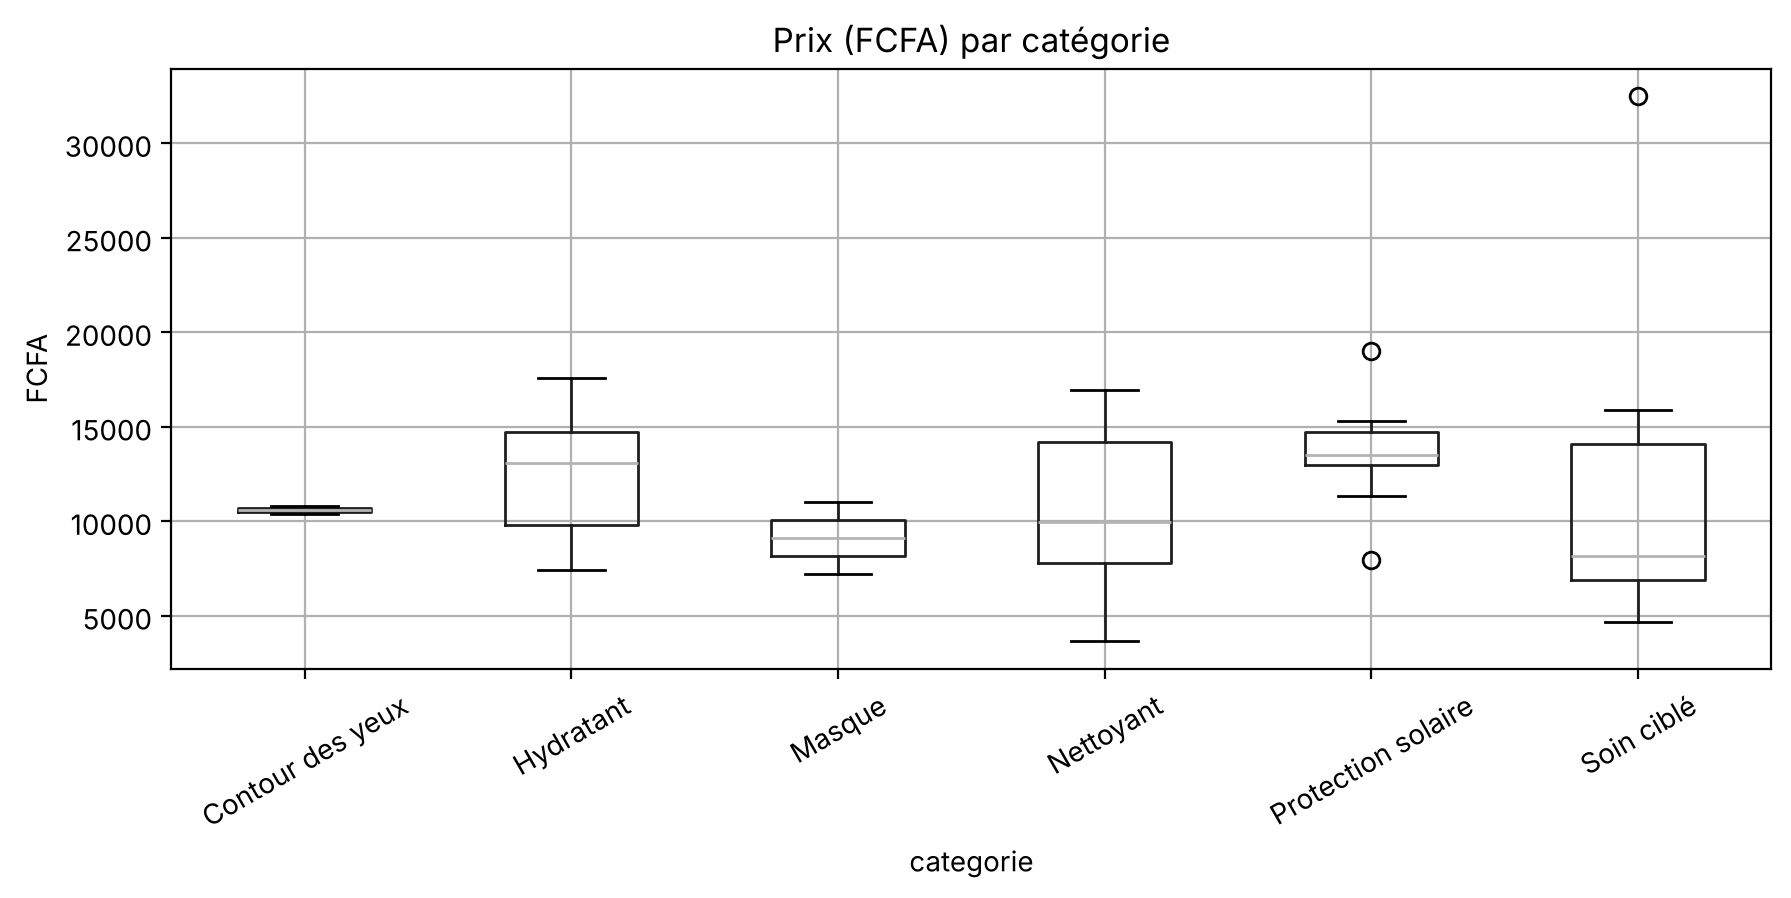

38 produits en promotion, remise moyenne : 17 %


In [4]:
print(df.groupby("categorie")["prix_fcfa"].describe()[["count", "min", "50%", "max"]].round(0))
df.boxplot(column="prix_fcfa", by="categorie", rot=30, figsize=(10, 4))
plt.suptitle(""); plt.title("Prix (FCFA) par catégorie"); plt.ylabel("FCFA"); plt.show()

promo = df["prix_barre_fcfa"].notna()
print(f"{promo.sum()} produits en promotion, remise moyenne :",
      round((1 - df.loc[promo, 'prix_fcfa'] / df.loc[promo, 'prix_barre_fcfa']).mean() * 100), "%")

## 4. Couverture des problèmes de peau
Combien de produits pour chaque problème que le modèle peut détecter ? Un problème avec peu de produits = moins de choix dans les recommandations.

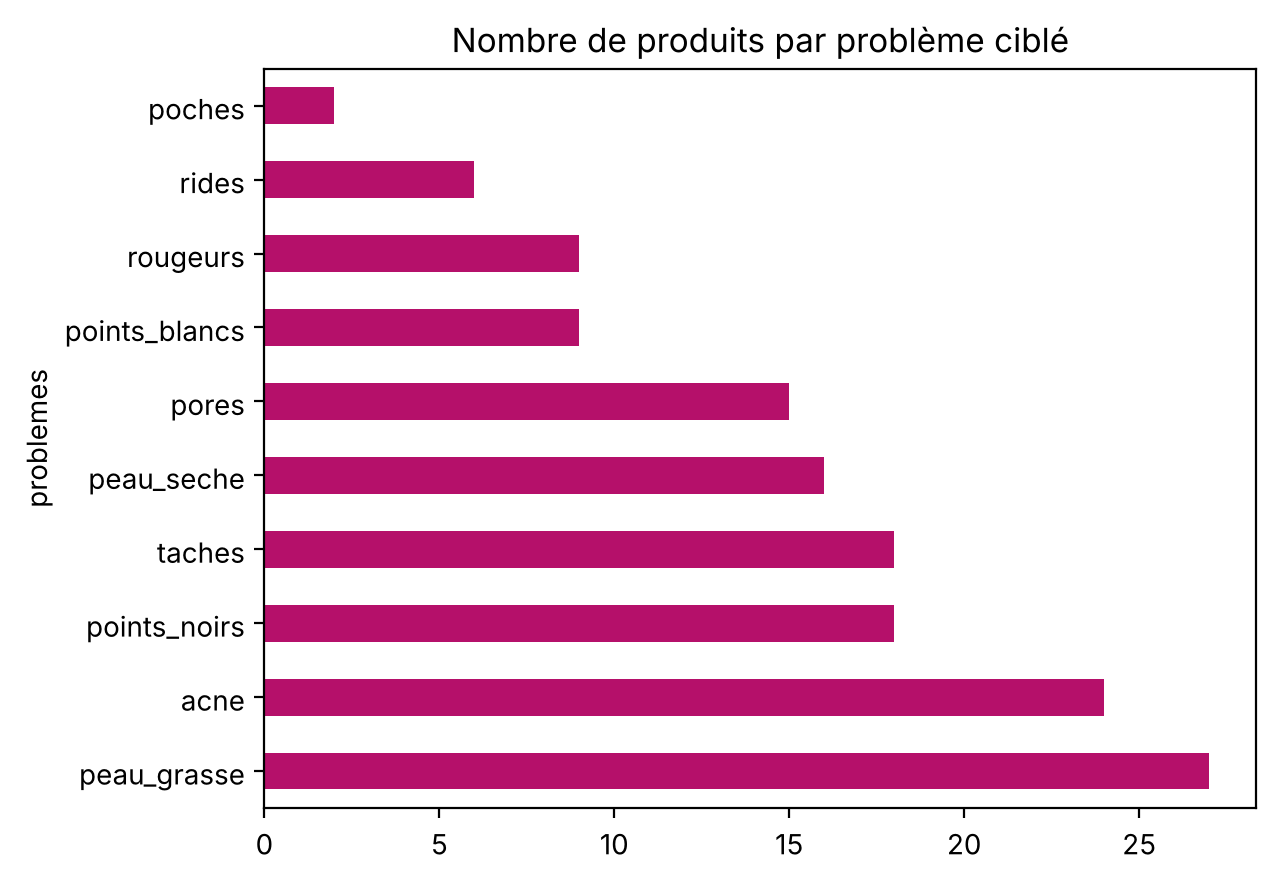

problemes
peau_grasse      27
acne             24
points_noirs     18
taches           18
peau_seche       16
pores            15
points_blancs     9
rougeurs          9
rides             6
poches            2
Name: count, dtype: int64


In [5]:
problemes = df["problemes"].str.split("|").explode()
problemes.value_counts().plot.barh(color="#B5106A", title="Nombre de produits par problème ciblé")
plt.show()
print(problemes.value_counts())

## 5. Adaptation au climat
Part des produits à texture légère (non grasse), importante sous le climat chaud et humide d'Abidjan.

In [6]:
print(df.groupby("categorie")["texture_legere"].mean().mul(100).round().astype(int).astype(str) + " %")
print("Total :", round(df["texture_legere"].mean() * 100), "% des produits ont une texture légère")

categorie
Contour des yeux      100 %
Hydratant              73 %
Masque                  0 %
Nettoyant             100 %
Protection solaire     90 %
Soin ciblé             89 %
Name: texture_legere, dtype: str
Total : 87 % des produits ont une texture légère


## Conclusions
- Le catalogue couvre bien l'**acné**, la **peau grasse**, les **points noirs** et les **taches brunes**, les problèmes les plus fréquents.
- **Poches/cernes** et **rides** ont peu de produits : à enrichir plus tard.
- Les prix vont de quelques milliers à ~30 000 FCFA : on peut proposer une routine complète à différents budgets.
- **Limites :** prix relevés à une date précise sur un seul site (ils changent), pas d'ingrédients détaillés, pas de notes clients fiables (trop peu d'avis).